# 01 — Data Audit

**Purpose:** establish the observed schema, verify the target, inspect data quality,
and assess provenance and leakage risk before any model is trained.

**Constraints:** the raw CSV is read-only; `Student_ID` is never a predictor;
`Overall_Impact` is withheld from default models pending evidence about its derivation.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
while not (ROOT / "src").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from sm_project import config, data, features, modeling, viz

config.ensure_output_dirs()
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
print("Project root:", ROOT)
print("Fixed seed:", config.SEED)

Project root: /Users/dhanudriya/Lecturer/ML-project-1
Fixed seed: 42


## 1. Load the source data and record its fingerprint

In [2]:
df, csv_path = data.read_data_with_source()
sha256 = hashlib.sha256(csv_path.read_bytes()).hexdigest()
print("Resolved source:", csv_path)
print("SHA-256 of raw file:", sha256)
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
display(df.head())
display(df.dtypes.rename("dtype").to_frame())

Resolved source: /Users/dhanudriya/Lecturer/ML-project-1/data/raw/Social_media_impact_on_life.csv
SHA-256 of raw file: 893bcfc9165dc2d92caf2511bc10a0753b67df22c2a370a43b513f2417468a3f
Rows: 4500 | Columns: 16


,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024000,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
1,STU_2024001,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
2,STU_2024002,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,Neutral
3,STU_2024003,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial
4,STU_2024004,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,Beneficial


,dtype
Student_ID,object
Age,int64
Gender,object
Academic_Level,object
Primary_Platform,object
Daily_Usage_Hours,float64
Weekend_Extra_Hours,float64
Device_Type,object
Sleep_Duration_Hours,float64
Sleep_Quality_Score,int64


## 2. Schema check against the documented expected columns

In [3]:
schema_check = data.check_expected_columns(df)
schema_table = pd.DataFrame(
    {
        "column": schema_check["expected"],
        "observed": [c in schema_check["observed"] for c in schema_check["expected"]],
    }
)
display(schema_table)
print("Missing expected columns:", schema_check["missing"])
print("Unexpected columns:", schema_check["unexpected"])
schema_table.to_csv(config.TABLES_DIR / "01_schema_check.csv", index=False)
assert not schema_check["missing"], "Expected columns are missing."

,column,observed
0,Student_ID,True
1,Age,True
2,Gender,True
3,Academic_Level,True
4,Primary_Platform,True
5,Daily_Usage_Hours,True
6,Weekend_Extra_Hours,True
7,Sleep_Duration_Hours,True
8,Sleep_Quality_Score,True
9,Perceived_Stress_Score,True


Missing expected columns: []
Unexpected columns: []


## 3. Missingness

,n_missing,pct_missing,dtype
Academic_Performance_GPA,85,1.89,float64
Perceived_Stress_Score,46,1.02,float64
Student_ID,0,0.00,object
Age,0,0.00,int64
Gender,0,0.00,object
Academic_Level,0,0.00,object
Primary_Platform,0,0.00,object
Daily_Usage_Hours,0,0.00,float64
Weekend_Extra_Hours,0,0.00,float64
Device_Type,0,0.00,object


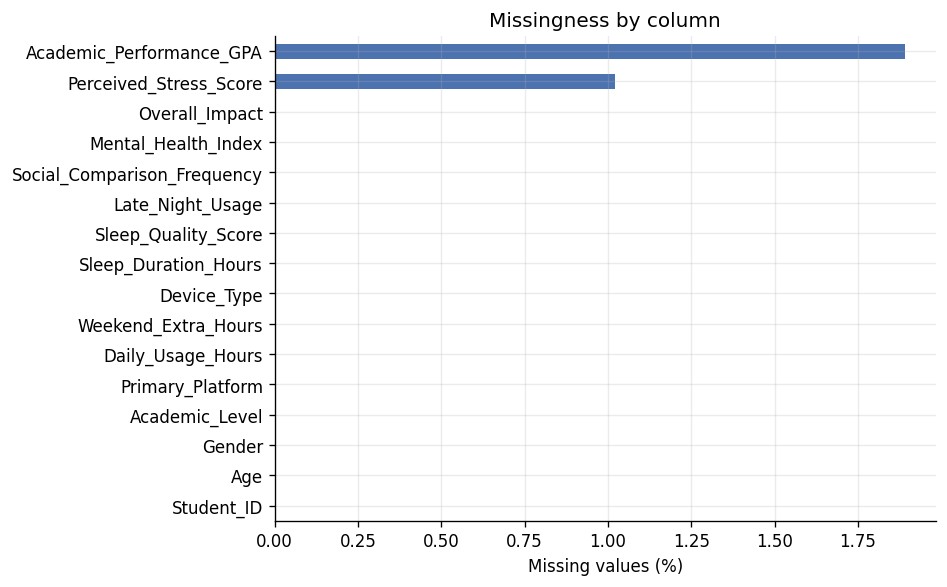

PosixPath('/Users/dhanudriya/Lecturer/ML-project-1/outputs/figures/01_missingness.png')

In [4]:
missing = pd.DataFrame(
    {
        "n_missing": df.isna().sum(),
        "pct_missing": (df.isna().mean() * 100).round(2),
        "dtype": df.dtypes.astype(str),
    }
).sort_values("n_missing", ascending=False)
display(missing)
missing.to_csv(config.TABLES_DIR / "01_missingness.csv")

fig, ax = plt.subplots(figsize=(8, 5))
order = missing["pct_missing"].sort_values()
order.plot.barh(ax=ax, color="#4C72B0")
ax.set_xlabel("Missing values (%)")
ax.set_ylabel("")
ax.set_title("Missingness by column")
viz.finish_figure(fig, "01_missingness.png")

## 4. Duplicate rows and identifier behaviour

In [5]:
n_duplicate_rows = int(df.duplicated().sum())
n_duplicate_ids = int(df["Student_ID"].duplicated().sum())
print("Exact duplicate rows:", n_duplicate_rows)
print("Duplicate Student_ID values:", n_duplicate_ids)
print("Unique Student_ID values:", df["Student_ID"].nunique(), "of", len(df))

id_text = df["Student_ID"].astype(str)
if id_text.str.fullmatch(r"STU_\d+").all():
    id_numbers = id_text.str.extract(r"(\d+)")[0].astype(int)
    contiguous = (id_numbers.max() - id_numbers.min() + 1) == len(df)
    print("ID numeric range:", id_numbers.min(), "to", id_numbers.max())
    print("Contiguous identifier sequence:", contiguous)
else:
    print("Identifier does not follow the expected STU_<digits> pattern.")

pd.DataFrame(
    {
        "check": ["duplicate_rows", "duplicate_ids", "unique_ids", "n_rows"],
        "value": [n_duplicate_rows, n_duplicate_ids, df["Student_ID"].nunique(), len(df)],
    }
).to_csv(config.TABLES_DIR / "01_identifier_checks.csv", index=False)

Exact duplicate rows: 0
Duplicate Student_ID values: 0
Unique Student_ID values: 4500 of 4500
ID numeric range: 2024000 to 2028499
Contiguous identifier sequence: True


## 5. Target validation

The target is **not assumed** to lie on a conventional 0–4 or 0–5 scale. We report
the observed range, missingness, granularity, and evidence of ceiling effects.

,value
n_rows,4500.000000
n_missing_target,85.000000
n_usable_target,4415.000000
min,1.900000
max,4.000000
mean,3.429282
std,0.392662
median,3.460000
n_unique,194.000000


Target values at observed maximum: 353
Target values below 2.0: 6
All target values are multiples of 0.01: True


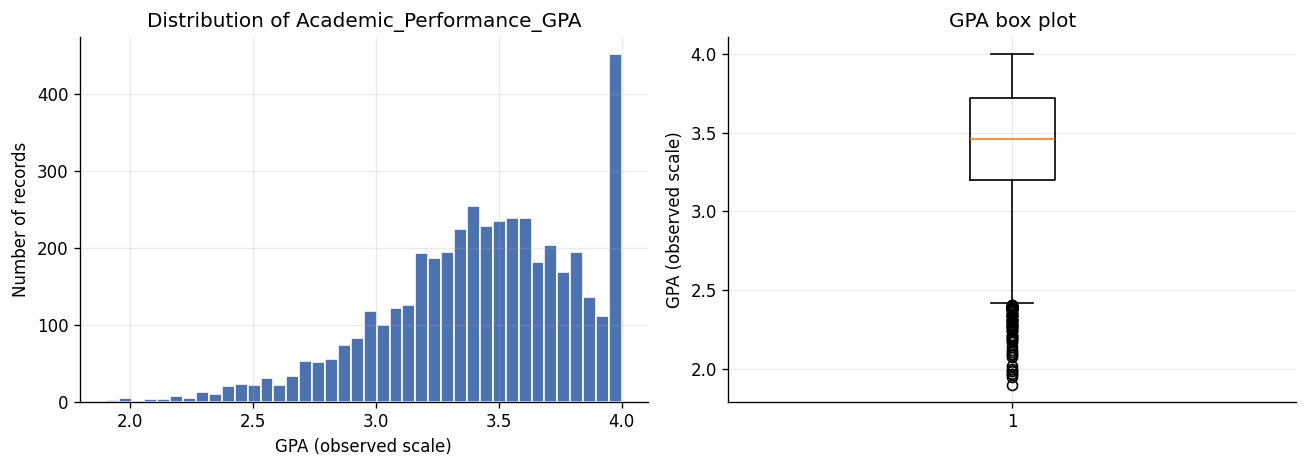

PosixPath('/Users/dhanudriya/Lecturer/ML-project-1/outputs/figures/01_target_distribution.png')

In [6]:
target = df[config.TARGET]
usable = int(target.notna().sum())
target_stats = {
    "n_rows": int(len(df)),
    "n_missing_target": int(target.isna().sum()),
    "n_usable_target": usable,
    "min": float(target.min()),
    "max": float(target.max()),
    "mean": float(target.mean()),
    "std": float(target.std()),
    "median": float(target.median()),
    "n_unique": int(target.nunique()),
}
display(pd.Series(target_stats, name="value").to_frame())
print("Target values at observed maximum:", int((target == target.max()).sum()))
print("Target values below 2.0:", int((target < 2.0).sum()))
print("All target values are multiples of 0.01:",
      bool(np.allclose(target.dropna() * 100, np.round(target.dropna() * 100))))

target_stats_df = pd.Series(target_stats, name="value").to_frame()
target_stats_df.to_csv(config.TABLES_DIR / "01_target_summary.csv")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(target.dropna(), bins=40, color="#4C72B0", edgecolor="white")
axes[0].set_title("Distribution of Academic_Performance_GPA")
axes[0].set_xlabel("GPA (observed scale)")
axes[0].set_ylabel("Number of records")
axes[1].boxplot(target.dropna(), vert=True)
axes[1].set_title("GPA box plot")
axes[1].set_ylabel("GPA (observed scale)")
viz.finish_figure(fig, "01_target_distribution.png")

## 6. Numeric and categorical summaries

In [7]:
numeric_summary = df.select_dtypes(include="number").describe().T
numeric_summary["missing"] = df.select_dtypes(include="number").isna().sum()
display(numeric_summary)
numeric_summary.to_csv(config.TABLES_DIR / "01_numeric_summary.csv")

rows = []
for column in df.select_dtypes(include=["object", "bool"]).columns:
    if column == "Student_ID":
        continue
    counts = df[column].value_counts(dropna=False)
    for value, count in counts.items():
        rows.append({"column": column, "value": value, "count": int(count),
                     "pct": round(100 * count / len(df), 2)})
category_summary = pd.DataFrame(rows)
category_summary.to_csv(config.TABLES_DIR / "01_category_summary.csv", index=False)
display(category_summary.groupby("column").head(10))

,count,mean,std,min,25%,50%,75%,max,missing
Age,4500.0,18.703333,1.981182,15.0,17.0,19.00,20.00,26.0,0
Daily_Usage_Hours,4500.0,5.295933,2.604497,0.9,3.4,4.70,6.60,14.0,0
Weekend_Extra_Hours,4500.0,1.796844,0.699245,0.0,1.3,1.80,2.30,4.5,0
Sleep_Duration_Hours,4500.0,6.701333,1.189998,3.0,6.0,6.80,7.50,10.5,0
Sleep_Quality_Score,4500.0,2.472000,1.030484,1.0,2.0,3.00,3.00,5.0,0
Perceived_Stress_Score,4454.0,13.512124,7.072859,0.0,9.0,13.00,18.00,40.0,46
Mental_Health_Index,4500.0,79.873111,12.876044,32.0,72.0,82.00,89.00,98.0,0
Academic_Performance_GPA,4415.0,3.429282,0.392662,1.9,3.2,3.46,3.72,4.0,85


,column,value,count,pct
0,Gender,Female,2234,49.64
1,Gender,Male,2051,45.58
2,Gender,Non-Binary,122,2.71
3,Gender,Prefer not to say,93,2.07
4,Academic_Level,Undergraduate,2777,61.71
5,Academic_Level,High School,1477,32.82
6,Academic_Level,Postgraduate,246,5.47
7,Primary_Platform,Instagram,1453,32.29
8,Primary_Platform,TikTok,1226,27.24
9,Primary_Platform,YouTube,818,18.18


## 7. Correlation structure and suspicious relationships

,Age,Daily_Usage_Hours,Weekend_Extra_Hours,Sleep_Duration_Hours,Sleep_Quality_Score,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA
Age,1.000,-0.030,0.003,0.013,0.031,-0.021,0.023,0.028
Daily_Usage_Hours,-0.030,1.000,-0.010,-0.716,-0.681,0.754,-0.850,-0.710
Weekend_Extra_Hours,0.003,-0.010,1.000,0.017,0.012,0.001,0.004,0.012
Sleep_Duration_Hours,0.013,-0.716,0.017,1.000,0.748,-0.662,0.774,0.595
Sleep_Quality_Score,0.031,-0.681,0.012,0.748,1.000,-0.576,0.662,0.529
Perceived_Stress_Score,-0.021,0.754,0.001,-0.662,-0.576,1.000,-0.774,-0.651
Mental_Health_Index,0.023,-0.850,0.004,0.774,0.662,-0.774,1.000,0.659
Academic_Performance_GPA,0.028,-0.710,0.012,0.595,0.529,-0.651,0.659,1.000


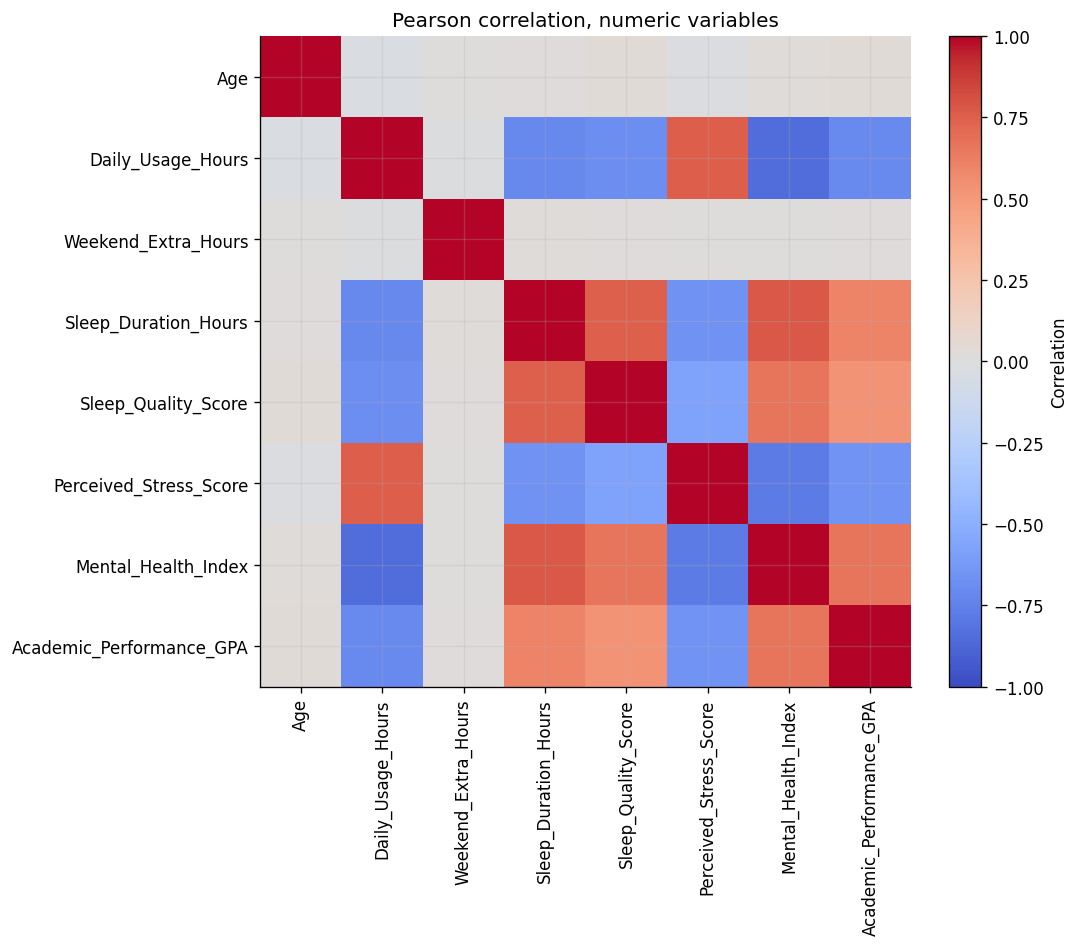

Correlation with target:


,pearson_r
Daily_Usage_Hours,-0.710057
Perceived_Stress_Score,-0.650921
Weekend_Extra_Hours,0.012275
Age,0.028110
Sleep_Quality_Score,0.529270
Sleep_Duration_Hours,0.595263
Mental_Health_Index,0.659419


Strongest predictor-predictor correlations (|r| > 0.7):


pearson_r
Daily_Usage_Hours      Mental_Health_Index       -0.849908
Sleep_Duration_Hours   Mental_Health_Index        0.774220
Perceived_Stress_Score Mental_Health_Index       -0.773744
Daily_Usage_Hours      Perceived_Stress_Score     0.754470
Sleep_Duration_Hours   Sleep_Quality_Score        0.747737
Daily_Usage_Hours      Sleep_Duration_Hours      -0.715903
                       Academic_Performance_GPA  -0.710057

In [8]:
numeric_df = df.select_dtypes(include="number")
correlation = numeric_df.corr()
correlation.to_csv(config.TABLES_DIR / "01_correlation_matrix.csv")
display(correlation.round(3))

fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlation.columns)))
ax.set_xticklabels(correlation.columns, rotation=90)
ax.set_yticks(range(len(correlation.columns)))
ax.set_yticklabels(correlation.columns)
ax.set_title("Pearson correlation, numeric variables")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="Correlation")
viz.finish_figure(fig, "01_correlation_heatmap.png")

target_corr = correlation[config.TARGET].drop(config.TARGET).sort_values()
print("Correlation with target:")
display(target_corr.to_frame("pearson_r"))

upper = correlation.where(
    np.triu(np.ones(correlation.shape, dtype=bool), k=1)
).stack().sort_values(key=np.abs, ascending=False)
print("Strongest predictor-predictor correlations (|r| > 0.7):")
display(upper[upper.abs() > 0.7].to_frame("pearson_r"))
upper.to_frame("pearson_r").to_csv(config.TABLES_DIR / "01_predictor_correlations.csv")

## 8. Leakage audit: `Student_ID` and `Overall_Impact`

`Student_ID` is an identifier and must never be a predictor. `Overall_Impact` is a
categorical summary that may have been derived from the target or from the same latent
variables. The tables below quantify that risk.

In [9]:
impact_table = (
    df.groupby("Overall_Impact")[config.TARGET]
      .agg(["count", "mean", "std", "min", "max"])
      .round(3)
)
display(impact_table)
impact_table.to_csv(config.TABLES_DIR / "01_overall_impact_vs_target.csv")

print("Overall_Impact category by target band:")
bands = pd.cut(df[config.TARGET], bins=[0, 2.5, 3.0, 3.5, 4.01],
               labels=["<=2.5", "2.5-3.0", "3.0-3.5", "3.5-4.0"])
display(pd.crosstab(df["Overall_Impact"], bands, dropna=False))

,count,mean,std,min,max
Overall_Impact,,,,,
Beneficial,3610,3.546,0.299,2.52,4.00
Negative,163,2.544,0.274,1.90,3.28
Neutral,642,2.997,0.278,2.09,3.81


Overall_Impact category by target band:


Academic_Performance_GPA,<=2.5,2.5-3.0,3.0-3.5,3.5-4.0
Overall_Impact,,,,
Beneficial,0,143,1476,1991
Negative,75,83,5,0
Neutral,26,305,292,19


## 9. Provenance evidence and synthetic-data fingerprints

In [10]:
deci = np.round((target.dropna() * 100) % 10).astype(int)
last_digit_counts = deci.value_counts().sort_index()
print("Last-digit distribution of GPA (percentiles):")
display(last_digit_counts.describe().to_frame("value"))
print("Observed counts by last digit:")
display(last_digit_counts.to_frame("count"))

def eta_squared(frame, categorical, numeric):
    frame = frame[[categorical, numeric]].dropna()
    grand_mean = frame[numeric].mean()
    ss_total = ((frame[numeric] - grand_mean) ** 2).sum()
    ss_between = 0.0
    for _, group in frame.groupby(categorical):
        ss_between += len(group) * (group[numeric].mean() - grand_mean) ** 2
    return ss_between / ss_total if ss_total else np.nan

eta_rows = []
for column in ["Gender", "Academic_Level", "Primary_Platform", "Device_Type",
               "Late_Night_Usage", "Social_Comparison_Frequency", "Overall_Impact"]:
    eta_rows.append({"column": column, "eta_squared_with_target": eta_squared(df, column, config.TARGET)})
eta_table = pd.DataFrame(eta_rows).sort_values("eta_squared_with_target", ascending=False)
display(eta_table)
eta_table.to_csv(config.TABLES_DIR / "01_categorical_association.csv", index=False)

# Range and grid checks
range_checks = []
for column in ["Age", "Daily_Usage_Hours", "Weekend_Extra_Hours",
               "Sleep_Duration_Hours", "Sleep_Quality_Score",
               "Perceived_Stress_Score", "Mental_Health_Index"]:
    series = df[column].dropna()
    steps = np.diff(np.sort(series.unique()))
    range_checks.append(
        {
            "column": column,
            "min": series.min(),
            "max": series.max(),
            "n_unique": series.nunique(),
            "smallest_step": float(steps.min()) if len(steps) else np.nan,
        }
    )
range_table = pd.DataFrame(range_checks)
display(range_table)
range_table.to_csv(config.TABLES_DIR / "01_range_checks.csv", index=False)

Last-digit distribution of GPA (percentiles):


,value
count,11.000000
mean,401.363636
std,167.197651
min,2.000000
25%,400.500000
50%,406.000000
75%,413.000000
max,746.000000


Observed counts by last digit:


,count
Academic_Performance_GPA,
0,746
1,409
2,405
3,411
4,429
5,391
6,406
7,405
8,415


,column,eta_squared_with_target
6,Overall_Impact,0.436354
4,Late_Night_Usage,0.064584
5,Social_Comparison_Frequency,0.000965
1,Academic_Level,0.000597
0,Gender,0.000519
2,Primary_Platform,0.000166
3,Device_Type,0.000011


,column,min,max,n_unique,smallest_step
0,Age,15.0,26.0,12,1.0
1,Daily_Usage_Hours,0.9,14.0,129,0.1
2,Weekend_Extra_Hours,0.0,4.5,43,0.1
3,Sleep_Duration_Hours,3.0,10.5,73,0.1
4,Sleep_Quality_Score,1.0,5.0,5,1.0
5,Perceived_Stress_Score,0.0,40.0,41,1.0
6,Mental_Health_Index,32.0,98.0,67,1.0


## 10. Audit conclusion and fitted report

In [11]:
strong_pairs = upper[upper.abs() > 0.7]
report_lines = [
    "# Data Audit Summary",
    "",
    f"- Source file: `{csv_path.name}` (SHA-256 `{sha256}`).",
    f"- Shape: {len(df):,} rows x {df.shape[1]} columns; missing expected columns: {schema_check['missing'] or 'none'}.",
    f"- Duplicate rows: {n_duplicate_rows}; duplicated Student_IDs: {n_duplicate_ids}; unique IDs: {df['Student_ID'].nunique():,}.",
    f"- Target range: {target.min():.2f} to {target.max():.2f}; mean {target.mean():.3f}; "
    f"missing {int(target.isna().sum())}; usable observations {usable:,}.",
    f"- Observations recorded exactly at the maximum GPA: {int((target == target.max()).sum())} (possible ceiling/cap).",
    f"- Predictor-pair correlations above |0.70|: {len(strong_pairs)}. Strongest: "
    + "; ".join(f"{a}-{b} r={v:.2f}" for (a, b), v in strong_pairs.head(5).items()) + ".",
    f"- Overall_Impact category means: "
    + "; ".join(f"{k}={v:.2f}" for k, v in impact_table['mean'].items()) + ".",
    "",
    "## Provenance status",
    "",
    "**Unknown.** No codebook, collection statement, or provider metadata accompanies the CSV. "
    "The file nevertheless shows several synthetic-data fingerprints: values on regular decimal grids, "
    "a near-uniform last decimal digit of the GPA, a capped maximum, and extremely strong multicollinearity "
    "among usage/sleep/stress/mental-health variables. Most categorical variables have near-zero association "
    "with the target, with Late_Night_Usage a modest exception (eta-squared about 0.06). These patterns are "
    "consistent with simulated data and do not establish real-student provenance.",
    "",
    "## Leakage decisions",
    "",
    "- `Student_ID` is excluded from all predictors.",
    "- `Overall_Impact` is excluded from default models. It is strongly associated with the target "
    "(eta-squared about 0.44) and its derivation is undocumented, so it cannot be treated as a legitimate predictor.",
    "- The target is never used to construct predictors.",
    "- Missing target rows are excluded from supervised analysis; predictor missingness is imputed inside pipelines.",
    "",
    "## Modelling gate",
    "",
    "Audit checks pass for modelling **only under these exclusions**. Findings describe the supplied file; "
    "they must not be generalized to a real student population without documented provenance.",
]
audit_text = "\n".join(report_lines)
(config.REPORTS_DIR / "01_data_audit.md").write_text(audit_text, encoding="utf-8")
display(Markdown(audit_text))

# Data Audit Summary

- Source file: `Social_media_impact_on_life.csv` (SHA-256 `893bcfc9165dc2d92caf2511bc10a0753b67df22c2a370a43b513f2417468a3f`).
- Shape: 4,500 rows x 16 columns; missing expected columns: none.
- Duplicate rows: 0; duplicated Student_IDs: 0; unique IDs: 4,500.
- Target range: 1.90 to 4.00; mean 3.429; missing 85; usable observations 4,415.
- Observations recorded exactly at the maximum GPA: 353 (possible ceiling/cap).
- Predictor-pair correlations above |0.70|: 7. Strongest: Daily_Usage_Hours-Mental_Health_Index r=-0.85; Sleep_Duration_Hours-Mental_Health_Index r=0.77; Perceived_Stress_Score-Mental_Health_Index r=-0.77; Daily_Usage_Hours-Perceived_Stress_Score r=0.75; Sleep_Duration_Hours-Sleep_Quality_Score r=0.75.
- Overall_Impact category means: Beneficial=3.55; Negative=2.54; Neutral=3.00.

## Provenance status

**Unknown.** No codebook, collection statement, or provider metadata accompanies the CSV. The file nevertheless shows several synthetic-data fingerprints: values on regular decimal grids, a near-uniform last decimal digit of the GPA, a capped maximum, and extremely strong multicollinearity among usage/sleep/stress/mental-health variables. Most categorical variables have near-zero association with the target, with Late_Night_Usage a modest exception (eta-squared about 0.06). These patterns are consistent with simulated data and do not establish real-student provenance.

## Leakage decisions

- `Student_ID` is excluded from all predictors.
- `Overall_Impact` is excluded from default models. It is strongly associated with the target (eta-squared about 0.44) and its derivation is undocumented, so it cannot be treated as a legitimate predictor.
- The target is never used to construct predictors.
- Missing target rows are excluded from supervised analysis; predictor missingness is imputed inside pipelines.

## Modelling gate

Audit checks pass for modelling **only under these exclusions**. Findings describe the supplied file; they must not be generalized to a real student population without documented provenance.